In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('penguins.csv', sep=r'\s*,\s*', engine='python')

In [3]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


---

## 4. Data Preprocessing

### 4.1 Memeriksa dan Menangani Missing Value dan Duplikasi Data

In [4]:
print("--- Jumlah Missing Value ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df[df.duplicated()])

--- Jumlah Missing Value ---
culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

--- Jumlah Duplikasi Data ---
     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex
339               NaN              NaN                NaN          NaN  NaN


In [5]:
df = df.dropna(how='all')
df = df.drop_duplicates()
df = df.reset_index(drop=True)
print("--- Jumlah Missing Value Setelah Ditangani")
print(df.isnull().sum().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value Setelah Ditangani
7

--- Jumlah Duplikasi Data ---
0


### 4.2 Mengganti Missing Value pada Kolom `sex` dengan Menggunakan Unknown

In [6]:
df['sex'] = (df['sex'].astype('string').str.strip().replace({'': pd.NA, '.': pd.NA}))
df['sex'] = df['sex'].fillna("Unknown")
print(df['sex'].value_counts(dropna=False))
print("\nJumlah Missing Value: ", df.isnull().sum().sum())

sex
MALE       169
FEMALE     165
Unknown      8
Name: count, dtype: Int64

Jumlah Missing Value:  0


### 4.3 Memeriksa dan Menangani Outliers pada Seluruh Kolom Numerik

In [7]:
kolom_numerik = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

for col in kolom_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)
    
    outliers = (df[col] < batas_bawah) | (df[col] > batas_atas)
    print(f"Outlier pada {col}: {outliers.sum()} baris")
    
    if outliers.sum() > 0:
        df.loc[outliers, col] = np.nan
        df[col] = df[col].fillna(df[col].median())

print("\nTotal Missing Value setelah penanganan outlier:", df.isnull().sum().sum())

Outlier pada culmen_length_mm: 0 baris
Outlier pada culmen_depth_mm: 0 baris
Outlier pada flipper_length_mm: 2 baris
Outlier pada body_mass_g: 0 baris

Total Missing Value setelah penanganan outlier: 0


### 4.4 Mengubah Kolom `sex` Menjadi Nilai Numerik Biner dan Memasukkan ke Dalam Kolom Fitur ($X$)

In [8]:
df_encoded = pd.get_dummies(df, columns=['sex'], prefix='sex', dtype=int)

print("Kolom Terbaru:", df_encoded.columns.tolist())

kolom_fitur = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex_FEMALE', 'sex_MALE', 'sex_Unknown']

X = df_encoded[kolom_fitur].copy()
print("Ukuran matriks fitur X:", X.shape)

Kolom Terbaru: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex_FEMALE', 'sex_MALE', 'sex_Unknown']
Ukuran matriks fitur X: (342, 7)


### 4.5 Melakukan Standardisasi pada Kolom Fitur 

In [9]:
mean_X = X.mean(axis=0)
std_X = X.std(axis=0, ddof=0)

X_scaled_df = (X - mean_X) / std_X

scaled_data = X_scaled_df.to_numpy()

X_scaled_df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE,sex_Unknown
count,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02
mean,1.662088e-16,-1.412775e-15,-8.310441e-16,4.155221e-17,9.349247e-17,-1.428357e-17,-2.597013e-17
std,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00
min,-2.168526e+00,-2.054446e+00,-2.062055e+00,-1.875362e+00,-9.655068e-01,-9.883717e-01,-1.547646e-01
25%,-8.615697e-01,-7.866355e-01,-7.791837e-01,-8.138982e-01,-9.655068e-01,-9.883717e-01,-1.547646e-01
50%,9.686524e-02,7.547549e-02,-2.802894e-01,-1.895079e-01,-9.655068e-01,-9.883717e-01,-1.547646e-01
75%,8.397670e-01,7.854492e-01,8.600404e-01,6.846384e-01,1.035725e+00,1.011765e+00,-1.547646e-01
max,2.875868e+00,2.205397e+00,2.142912e+00,2.620248e+00,1.035725e+00,1.011765e+00,6.461424e+00


---

## 5. Modelling

### 5.1 

In [10]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

### 5.2 

In [11]:
class KMeans:
    def __init__(self, K=3, max_iters=100, plot_steps=False):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps

        self.clusters = [[] for _ in range(self.K)]
        self.centroids = []

    def predict(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape

        random_sample_idxs = np.random.choice(self.n_samples, self.K, replace=False)
        self.centroids = [self.X[idx] for idx in random_sample_idxs]

        for _ in range(self.max_iters):
            self.clusters = self._create_clusters(self.centroids)

            if self.plot_steps:
                self.plot()

            centroids_old = self.centroids
            self.centroids = self._get_centroids(self.clusters)

            if self._is_converged(centroids_old, self.centroids):
                break

            if self.plot_steps:
                self.plot()

        return self._get_cluster_labels(self.clusters)

    def _get_cluster_labels(self, clusters):
        labels = np.empty(self.n_samples, dtype=int)
        for cluster_idx, cluster in enumerate(clusters):
            for sample_idx in cluster:
                labels[sample_idx] = cluster_idx
        return labels

    def _create_clusters(self, centroids):
        clusters = [[] for _ in range(self.K)]
        for idx, sample in enumerate(self.X):
            centroid_idx = self._closest_centroid(sample, centroids)
            clusters[centroid_idx].append(idx)
        return clusters

    def _closest_centroid(self, sample, centroids):
        distances = [euclidean_distance(sample, point) for point in centroids]
        closest_idx = np.argmin(distances)
        return closest_idx

    def _get_centroids(self, clusters):
        centroids = np.zeros((self.K, self.n_features))
        for cluster_idx, cluster in enumerate(clusters):
            if len(cluster) > 0:
                cluster_mean = np.mean(self.X[cluster], axis=0)
                centroids[cluster_idx] = cluster_mean
            else:
                centroids[cluster_idx] = self.centroids[cluster_idx]
        return centroids

    def _is_converged(self, centroids_old, centroids):
        distances = [euclidean_distance(centroids_old[i], centroids[i]) for i in range(self.K)]
        return sum(distances) == 0

    def plot(self, feat_x=2, feat_y=3):
        fig, ax = plt.subplots(figsize=(8, 5))
        for i, index in enumerate(self.clusters):
            point = self.X[index][:, [feat_x, feat_y]].T
            ax.scatter(*point, label=f"Cluster {i}")

        for point in self.centroids:
            ax.scatter(point[feat_x], point[feat_y], marker="x", color="black", s=150, linewidth=3)

        ax.set_xlabel("Flipper Length (Scaled)")
        ax.set_ylabel("Body Mass (Scaled)")
        ax.legend()
        plt.show()

### 5.3 

In [12]:
np.random.seed(42)

K_pilihan = 3
kmeans_model = KMeans(K=K_pilihan, max_iters=100, plot_steps=False)
cluster_labels = kmeans_model.predict(scaled_data)

df['Cluster'] = cluster_labels

print(f"Model K-Means (K={K_pilihan}) berhasil dijalankan!")
print("\nDistribusi Jumlah Anggota per Cluster:")
print(df['Cluster'].value_counts().sort_index())

Model K-Means (K=3) berhasil dijalankan!

Distribusi Jumlah Anggota per Cluster:
Cluster
0    123
1    108
2    111
Name: count, dtype: int64


---

## 6. Evaluation

### 6.1

Jumlah Cluster K = 1 --> WCSS (SSE) = 2394.00
Jumlah Cluster K = 2 --> WCSS (SSE) = 1591.10
Jumlah Cluster K = 3 --> WCSS (SSE) = 1067.80
Jumlah Cluster K = 4 --> WCSS (SSE) = 766.22
Jumlah Cluster K = 5 --> WCSS (SSE) = 660.11
Jumlah Cluster K = 6 --> WCSS (SSE) = 318.75


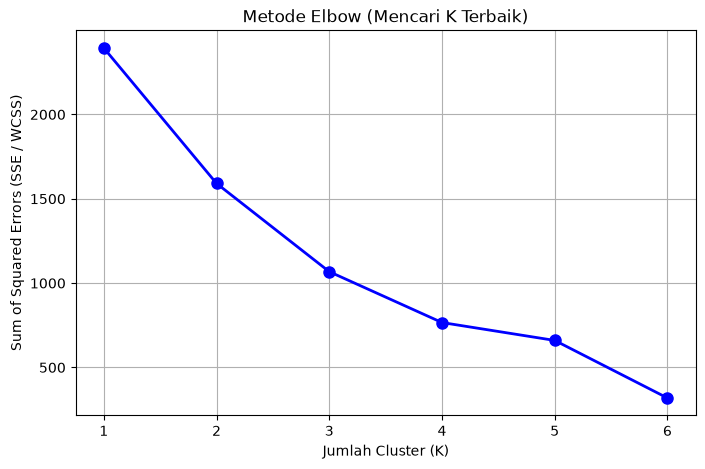

In [13]:
def hitung_wcss(X, labels, centroids):
    wcss = 0
    for i, centroid in enumerate(centroids):
        cluster_points = X[labels == i]
        if len(cluster_points) > 0:
            wcss += np.sum((cluster_points - centroid) ** 2)
    return wcss

ks = range(1, 7)
sse_list = []

for k in ks:
    np.random.seed(42)
    model_uji = KMeans(K=k, max_iters=100)
    labels_uji = model_uji.predict(scaled_data)
    nilai_sse = hitung_wcss(scaled_data, labels_uji, model_uji.centroids)
    sse_list.append(nilai_sse)
    print(f"Jumlah Cluster K = {k} --> WCSS (SSE) = {nilai_sse:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(ks, sse_list, 'bo-', linewidth=2, markersize=8)
plt.title('Metode Elbow (Mencari K Terbaik)')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Sum of Squared Errors (SSE / WCSS)')
plt.grid(True)
plt.show()

Jumlah Cluster K = 2 --> Silhouette Score = 0.3768
Jumlah Cluster K = 3 --> Silhouette Score = 0.4462
Jumlah Cluster K = 4 --> Silhouette Score = 0.5348
Jumlah Cluster K = 5 --> Silhouette Score = 0.5199
Jumlah Cluster K = 6 --> Silhouette Score = 0.5679


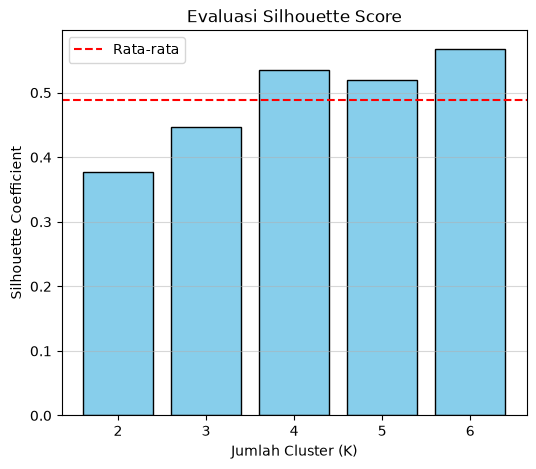

In [14]:
def hitung_silhouette_score(X, labels):
    n = len(X)
    unique_labels = np.unique(labels)
    if len(unique_labels) <= 1:
        return 0.0
    
    dist_matrix = np.sqrt(np.sum((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2, axis=2))
    
    s_scores = np.zeros(n)
    for i in range(n):
        own_cluster = labels[i]
        mask_own = (labels == own_cluster)
        mask_own[i] = False
        
        a_i = np.mean(dist_matrix[i, mask_own]) if np.sum(mask_own) > 0 else 0.0
        
        b_i = np.inf
        for other_cluster in unique_labels:
            if other_cluster != own_cluster:
                mask_other = (labels == other_cluster)
                if np.sum(mask_other) > 0:
                    mean_dist_other = np.mean(dist_matrix[i, mask_other])
                    b_i = min(b_i, mean_dist_other)
                    
        s_scores[i] = (b_i - a_i) / max(a_i, b_i) if max(a_i, b_i) > 0 else 0.0
        
    return np.mean(s_scores)

k_range_sil = range(2, 7)
silhouette_list = []

for k in k_range_sil:
    np.random.seed(42)
    model_uji = KMeans(K=k, max_iters=100)
    labels_uji = model_uji.predict(scaled_data)
    skor_sil = hitung_silhouette_score(scaled_data, labels_uji)
    silhouette_list.append(skor_sil)
    print(f"Jumlah Cluster K = {k} --> Silhouette Score = {skor_sil:.4f}")

plt.figure(figsize=(6, 5))
plt.bar(k_range_sil, silhouette_list, color='skyblue', edgecolor='black')
plt.axhline(y=np.mean(silhouette_list), color='red', linestyle='--', label='Rata-rata')
plt.title('Evaluasi Silhouette Score')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Coefficient')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

=== Tabel Posisi Centroid pada Skala Fisik Asli ===
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  \
0             47.50            14.98             217.19      5076.02   
1             43.78            19.14             194.81      4012.50   
2             40.09            17.62             188.88      3417.12   

   sex_FEMALE  sex_MALE  sex_Unknown  
0        0.47       0.5         0.03  
1       -0.00       1.0         0.00  
2        0.96      -0.0         0.04  

=== Profil Rata-Rata Fisik Penguin Tiap Cluster ===
         culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
Cluster                                                                   
0                   47.50            14.98             217.19      5076.02
1                   43.78            19.14             194.81      4012.50
2                   40.09            17.62             188.88      3417.12

=== Distribusi Jenis Kelamin (Sex) Tiap Cluster ===
sex      FEMALE  MALE 

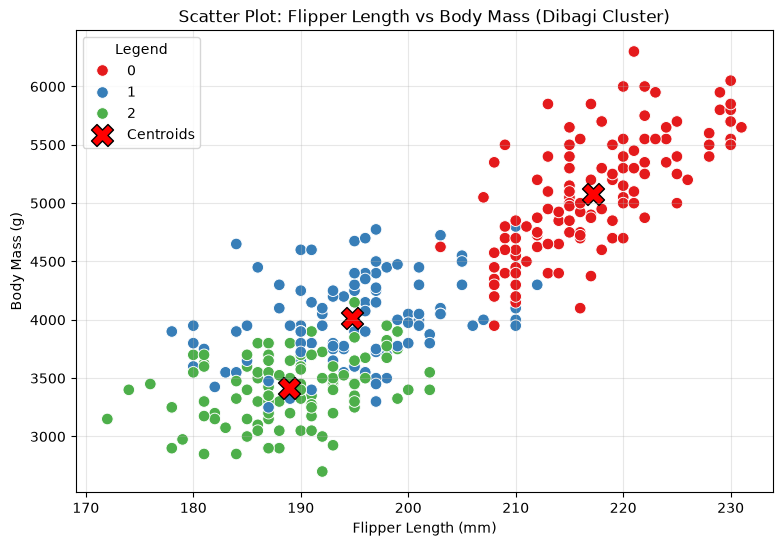

In [15]:
centroids_scaled = np.array(kmeans_model.centroids)
centroids_asli = (centroids_scaled * std_X.to_numpy()) + mean_X.to_numpy()
df_centroids = pd.DataFrame(centroids_asli, columns=kolom_fitur)

print("=== Tabel Posisi Centroid pada Skala Fisik Asli ===")
print(df_centroids.round(2))

print("\n=== Profil Rata-Rata Fisik Penguin Tiap Cluster ===")
print(df.groupby('Cluster')[kolom_numerik].mean().round(2))

print("\n=== Distribusi Jenis Kelamin (Sex) Tiap Cluster ===")
print(pd.crosstab(df['Cluster'], df['sex']))

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, 
    x='flipper_length_mm', 
    y='body_mass_g', 
    hue='Cluster', 
    palette='Set1', 
    s=70
)

plt.scatter(
    df_centroids['flipper_length_mm'], 
    df_centroids['body_mass_g'], 
    marker='X', 
    color='red', 
    s=250, 
    edgecolor='black', 
    label='Centroids'
)

plt.title('Scatter Plot: Flipper Length vs Body Mass (Dibagi Cluster)')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.legend(title='Legend')
plt.grid(True, alpha=0.3)
plt.show()